# Detection v3: the Sethi detector against the v7 evasive adversary

The detector and its scoring are v2's, unchanged (`detection/v2`, configs `paper`,
`no_propagation`, `theta_hi_1`). The data are the five `washtrade/v7` sweeps at 200 seeds
(104,000 runs). In v7 the wash group can use four tactics:

- **rotation**: each round trades a cycle over 3 wallets drawn from a pool of P;
- **random size**: a round of size Q (uniform on 1..hi) is split into Q unit trades;
- **residual**: the closing edge is off by delta, so wallets end rounds away from zero;
- **camouflage**: the pool wallets also trade as ZIs, at a total rate of 0.06.

New in v3: thresholds calibrated on control runs (`calibrate.py`), so that backgrounds can be
compared at the same false-positive rate.

This notebook only reads results. To (re)run detection, set `RUN_DETECTION = True` in the
configuration cell (about 1 hour with 15 jobs). Finished shards are skipped.

In [1]:
import os
import subprocess
import sys
import time
from pathlib import Path


def _find_root(start):
    for p in [start, *start.parents]:
        if (p / "marketsim").is_dir() and (p / "capstone codes").is_dir():
            return p
    raise RuntimeError("repository root not found above " + str(start))


ROOT = _find_root(Path.cwd().resolve())
for p in (str(ROOT), str(ROOT / "capstone codes")):
    if p not in sys.path:
        sys.path.insert(0, p)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from washtrade.v7 import design as D
from washtrade.v7 import generate as G
from detection.v3 import experiment as X

DET3 = ROOT / "capstone codes" / "detection" / "v3"

## Configuration

In [2]:
# Folder holding ds_v7_<sweep>/. Set the WASH_V7_DATA environment variable, or edit this line.
DATA = Path(os.environ.get("WASH_V7_DATA") or (ROOT / "capstone codes" / "washtrade" / "v7" / "data"))
RUN_DETECTION = False                 # True = smoke test + detection on every sweep (~1 h)
JOBS = max(1, (os.cpu_count() or 2) - 1)
SWEEPS = list(D.SWEEPS)
missing = [sw for sw in SWEEPS if not (Path(G.dataset_root(sw, out_dir=str(DATA))) / "manifest.csv").exists()]
print("sweeps:", SWEEPS, "| missing datasets:", missing or "none")

sweeps: ['scenarios', 'rotation', 'size', 'residual', 'evasive'] | missing datasets: none


## 1. Smoke test and detection (only if `RUN_DETECTION`)

In [3]:
if RUN_DETECTION:
    res = subprocess.run([sys.executable, str(DET3 / "run_smoke.py")], cwd=ROOT,
                         capture_output=True, text=True, encoding="utf-8")
    print(res.stdout.splitlines()[-1])
    if res.returncode != 0:
        raise RuntimeError("smoke test failed:\n" + res.stdout[-2000:])
    t0 = time.time()
    X.run_all(SWEEPS, jobs=JOBS, data=str(DATA))
    from detection.v3 import calibrate as CAL
    CAL.calibrate_all(str(DATA), verbose=False)
    print(f"detection done in {(time.time() - t0) / 60:.0f} min")
else:
    print("RUN_DETECTION is False: reading existing results")

RUN_DETECTION is False: reading existing results


## 2. Load results

In [4]:
def det_path(sw, table):
    return Path(G.dataset_root(sw, out_dir=str(DATA))) / "detection_v3" / f"{table}.csv"


METRICS = ["trade_avg_precision", "trade_fixed_recall", "trade_fixed_precision"]
CAL_METRICS = ["trade_recall", "trade_precision", "trade_fpr"]
MAN = ["run_id", "zero_returns_per_used_wallet", "events_per_pair_mean", "honest_zero_returns_per_agent"]


def load(sw):
    """paper config: one row per run, with v2 metrics, calibrated metrics and v7 run metrics."""
    r = pd.read_csv(det_path(sw, "results"))
    r = r[r["config"] == "paper"]
    c = pd.read_csv(det_path(sw, "calibrated"))
    c = c[c["config"] == "paper"][["run_id", "theta_cal"] + CAL_METRICS]
    m = pd.read_csv(Path(G.dataset_root(sw, out_dir=str(DATA))) / "manifest.csv", usecols=MAN)
    return r.merge(c, on="run_id").merge(m, on="run_id")


R = {sw: load(sw) for sw in SWEEPS}
TH = pd.read_csv(DATA / "detection_v3_thresholds.csv")
print({sw: f"{len(R[sw])} runs" for sw in SWEEPS})

BG4 = ["thin", "thick", "active", "active_dense"]
BG3 = ["thin", "thick", "active"]
BG5 = ["thin", "thick", "active_thin", "active", "active_dense"]
COLOR = {"thin": "#2a78d6", "thick": "#eb6834", "active_thin": "#eda100", "active": "#1baf7a",
         "active_dense": "#e87ba4"}                # same as detection v2
MARKER = {"thin": "o", "thick": "s", "active_thin": "D", "active": "^", "active_dense": "v"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.titlesize": 11, "axes.labelsize": 10,
    "legend.frameon": False, "lines.linewidth": 2, "lines.markersize": 6,
})


def mean_ci(df, by, col):
    out = df.groupby(by)[col].agg(["mean", "std", "count"]).reset_index()
    out["half"] = 1.96 * out["std"].fillna(0) / np.sqrt(out["count"])
    return out


def line_ci(ax, d, x, label, b, ls="-"):
    d = d.sort_values(x)
    ax.plot(d[x], d["mean"], ls, color=COLOR[b], marker=MARKER[b], label=label)
    ax.fill_between(d[x], d["mean"] - d["half"], d["mean"] + d["half"], color=COLOR[b],
                    alpha=0.15, linewidth=0)


def heat(ax, piv, vmin=0, vmax=1, cmap="Blues", fmt="{:.2f}"):
    ax.imshow(piv.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.grid(False)
    ax.set_xticks(range(piv.shape[1]), piv.columns, rotation=0)
    ax.set_yticks(range(piv.shape[0]), piv.index)
    for (i, j), v in np.ndenumerate(piv.values):
        if np.isfinite(v):
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=9,
                    color="white" if (v - vmin) / (vmax - vmin) > 0.6 else "#0b0b0b")

{'scenarios': '12000 runs', 'rotation': '14400 runs', 'size': '8400 runs', 'residual': '10800 runs', 'evasive': '58400 runs'}


## 3. Control-calibrated thresholds

For each background, `theta_cal` is the smallest $\theta$ on the grid 0.50, 0.51, ..., 1.00
whose pooled trade FPR over the background's 200 control runs (no wash trading) is at most 1%.
The table also shows the pooled FPR at the paper's $\theta = 0.9$. Without propagation
(`no_propagation`) no grid value reaches 1% in any background ($\theta_{cal} = \infty$).

The figure shows the pooled control FPR as a function of $\theta$ (`paper` config). The dashed
line is the 1% target.

,theta_cal,fpr_at_cal,fpr_at_0_9,n_control_runs
background,,,,
thin,0.84,0.0098,0.0042,200
thick,0.81,0.0093,0.0009,200
active_thin,0.99,0.0082,0.1439,200
active,0.98,0.0099,0.4354,200
active_dense,0.97,0.0037,0.4235,200


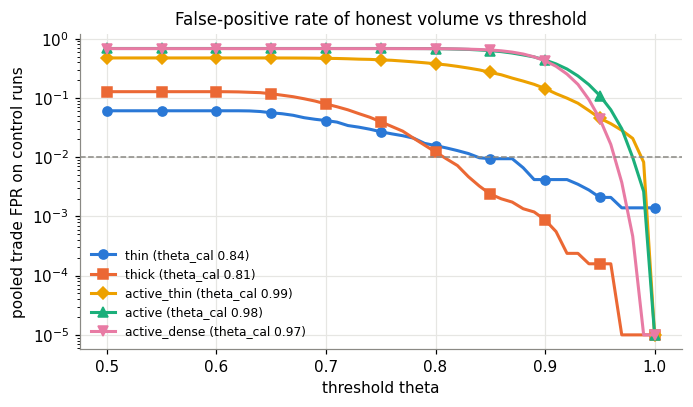

In [5]:
th = TH[TH["config"] == "paper"].set_index("background").reindex(BG5)
display(th[["theta_cal", "fpr_at_cal", "fpr_at_0_9", "n_control_runs"]].round(4))

cu = pd.read_csv(det_path("scenarios", "curves"),
                 usecols=["config", "f_scenario", "f_background", "theta", "trade_fp", "trade_neg"])
cu = cu[(cu["config"] == "paper") & (cu["f_scenario"] == "control")]
pool = cu.groupby(["f_background", "theta"])[["trade_fp", "trade_neg"]].sum().reset_index()
pool["fpr"] = pool["trade_fp"] / pool["trade_neg"]
fig, ax = plt.subplots(figsize=(6.4, 3.8))
for b in BG5:
    s = pool[pool["f_background"] == b]
    ax.plot(s["theta"], s["fpr"].clip(lower=1e-5), color=COLOR[b], marker=MARKER[b], markevery=5,
            label=f"{b} (theta_cal {th.loc[b, 'theta_cal']:.2f})")
ax.axhline(0.01, color="#8a8984", ls="--", lw=1)
ax.set_yscale("log")
ax.set_xlabel("threshold theta")
ax.set_ylabel("pooled trade FPR on control runs")
ax.set_title("False-positive rate of honest volume vs threshold")
ax.legend(fontsize=8)
fig.tight_layout()

## 4. Headline: the fixed triad vs all four tactics together

`evasive` sweep. **Baseline**: a fixed triad (pool 3, Q = 1, no residual, no camouflage).
**All four**: pool 96, Q in 1..4, residual on half of the rounds, camouflage. Seed means with
95% intervals (200 seeds per cell).

- Top row: average precision (AP) of the trade ranking. AP does not depend on a threshold.
- Bottom row: trade recall at the background's control-calibrated threshold.

trade_avg_precision             trade_recall              \
adversary                     all four fixed triad     all four fixed triad   
f_background f_gap                                                            
thin         0.0                  0.95        1.00         0.65        0.98   
             5.0                  0.91        0.99         0.58        0.90   
             20.0                 0.77        0.96         0.37        0.80   
thick        0.0                  0.92        1.00         0.69        0.97   
             5.0                  0.82        0.97         0.56        0.86   
             20.0                 0.59        0.85         0.34        0.81   
active       0.0                  0.53        0.95         0.08        0.45   
             5.0                  0.25        0.56         0.01        0.06   
             20.0                 0.11        0.07         0.00        0.02   
active_dense 0.0                  0.38        0.92         0.09        0.30   
             5.0                  0.12        0.15         0.02        0.01   
             20.0                 0.06        0.02         0.02        0.01   

                   trade_precision              
adversary                 all four fixed triad  
f_background f_gap                              
thin         0.0              0.97        1.00  
             5.0              0.95        0.98  
             20.0             0.87        0.93  
thick        0.0              0.94        0.97  
             5.0              0.87        0.89  
             20.0             0.69        0.76  
active       0.0              0.99        0.93  
             5.0              0.86        0.25  
             20.0             0.07        0.06  
active_dense 0.0              0.95        0.82  
             5.0              0.70        0.01  
             20.0             0.01        0.00

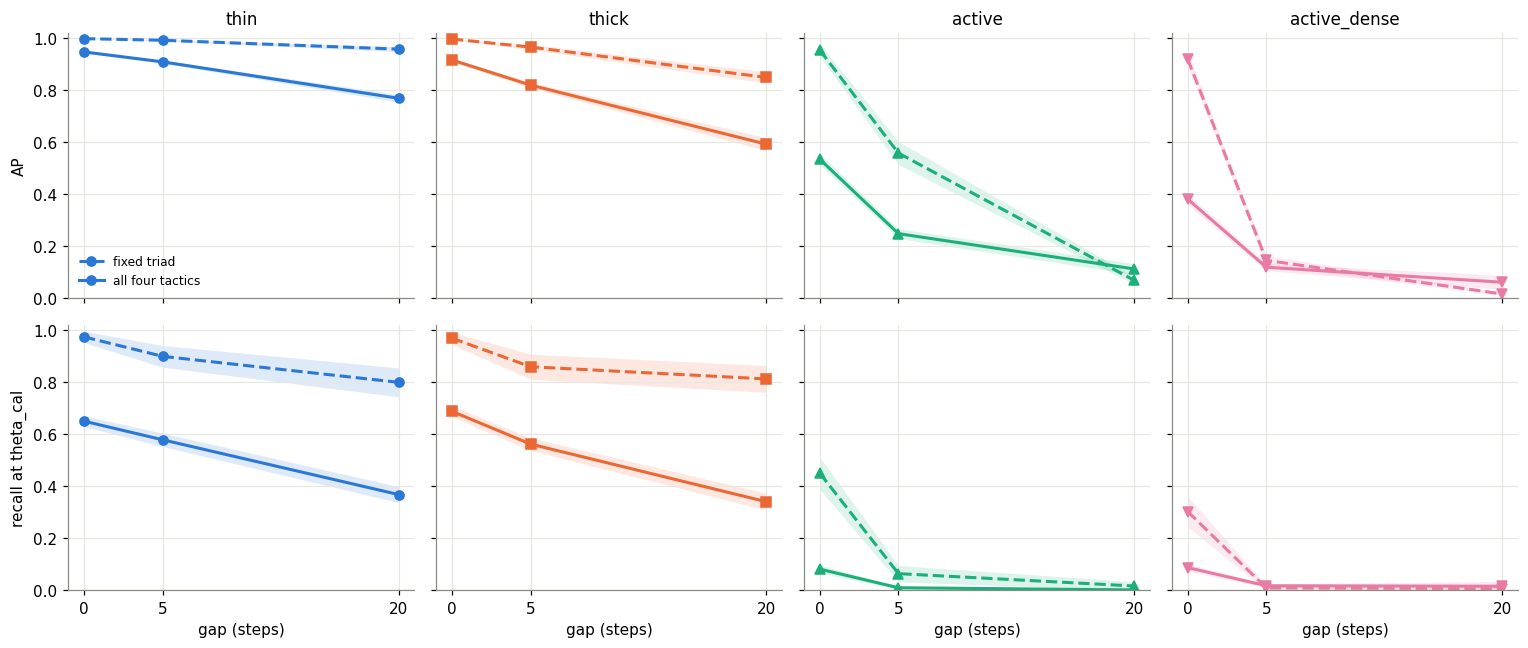

In [6]:
ev = R["evasive"]
w = ev[ev["f_scenario"] == "wash"].copy()
base = (w.f_pool == 3) & (w.f_q_hi == 1) & (w.f_residual_prob == 0) & (w.f_camouflage_total == 0)
allf = (w.f_pool == 96) & (w.f_q_hi == 4) & (w.f_residual_prob > 0) & (w.f_camouflage_total > 0)
fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharex=True, sharey=True)
for j, b in enumerate(BG4):
    for i, (col, ylab) in enumerate([("trade_avg_precision", "AP"),
                                     ("trade_recall", "recall at theta_cal")]):
        ax = axes[i][j]
        for mask, label, ls in ((base, "fixed triad", "--"), (allf, "all four tactics", "-")):
            s = w[mask & (w.f_background == b)]
            line_ci(ax, mean_ci(s, "f_gap", col), "f_gap", label, b, ls)
        ax.set_ylim(0, 1.02)
        ax.set_xticks([0, 5, 20])
        if i == 0:
            ax.set_title(b)
        if j == 0:
            ax.set_ylabel(ylab)
        if i == 1:
            ax.set_xlabel("gap (steps)")
axes[0][0].legend(fontsize=8, loc="lower left")
fig.tight_layout()

tab = w[base | allf].assign(adversary=np.where(base[base | allf], "fixed triad", "all four"))
display(tab.groupby(["f_background", "f_gap", "adversary"])[
    ["trade_avg_precision", "trade_recall", "trade_precision"]].mean().round(2)
    .unstack("adversary").reindex(BG4, level=0))

## 5. One tactic at a time (gap 0, no camouflage)

Each row adds one tactic to the fixed triad; the last row combines rotation (pool 96), size
(Q in 1..4) and residual (p = 0.5). Left: AP. Middle: recall at `theta_cal`. Right: how often a
wash wallet's net position returns to exactly zero during the run (all of its legs). This is
the event the detector's initial score counts.

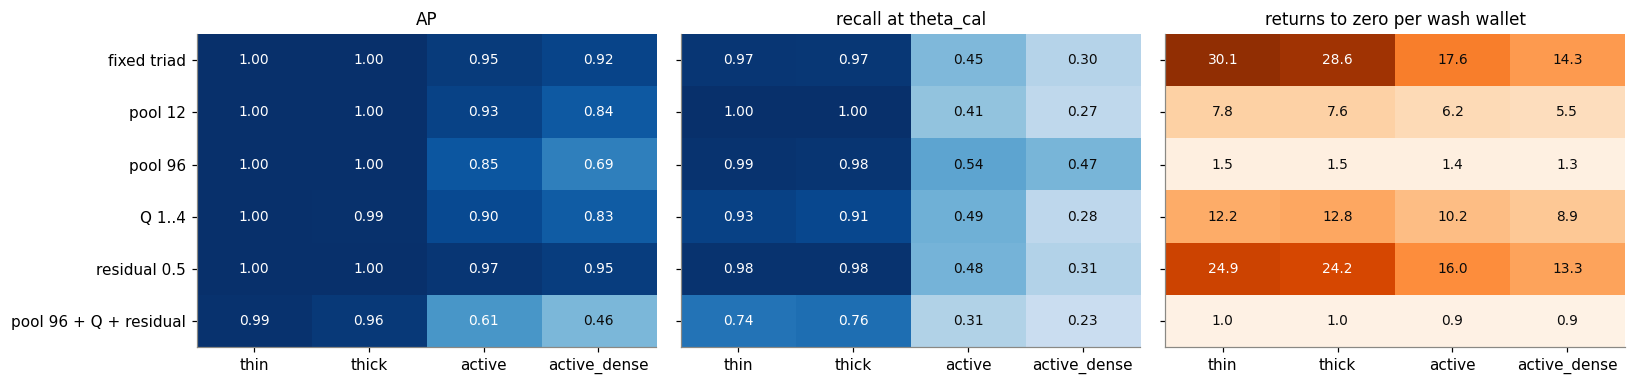

In [7]:
g0 = w[(w.f_gap == 0) & (w.f_camouflage_total == 0)]
TACTICS = [("fixed triad", (3, 1, 0)), ("pool 12", (12, 1, 0)), ("pool 96", (96, 1, 0)),
           ("Q 1..4", (3, 4, 0)), ("residual 0.5", (3, 1, 0.5)), ("pool 96 + Q + residual", (96, 4, 0.5))]
rows = []
for name, (pool_, q, res) in TACTICS:
    s = g0[(g0.f_pool == pool_) & (g0.f_q_hi == q) & (g0.f_residual_prob == res)]
    m = s.groupby("f_background")[["trade_avg_precision", "trade_recall",
                                   "zero_returns_per_used_wallet"]].mean()
    for b in BG4:
        rows.append(dict(tactic=name, background=b, **m.loc[b].to_dict()))
T = pd.DataFrame(rows)
order = [t for t, _ in TACTICS]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, (col, title, vmax, cmap, fmt) in zip(axes, [
        ("trade_avg_precision", "AP", 1, "Blues", "{:.2f}"),
        ("trade_recall", "recall at theta_cal", 1, "Blues", "{:.2f}"),
        ("zero_returns_per_used_wallet", "returns to zero per wash wallet", 32, "Oranges", "{:.1f}")]):
    piv = T.pivot(index="tactic", columns="background", values=col).reindex(order)[BG4]
    heat(ax, piv, vmax=vmax, cmap=cmap, fmt=fmt)
    ax.set_title(title)
for ax in axes[1:]:
    ax.set_yticklabels([])
fig.tight_layout()

## 6. Mechanism: the initial score is binary

In a single market the initial score is $x^0_i = 1$ if wallet $i$'s position ever returns to
zero, else 0. A wash wallet that closes once scores the same as one that closes 30 times. So
rotation alone (fewer closures per wallet) does not lower $x^0$. The score only falls when
wallets stop closing altogether, which needs few rounds per wallet (rotation) *and* inexact
closing (residual).

All wash runs of the `evasive` sweep at gap 0, binned by returns to zero per wash wallet.
Left: the group's volume-weighted initial score $\bar x^0$. Right: recall at `theta_cal`.

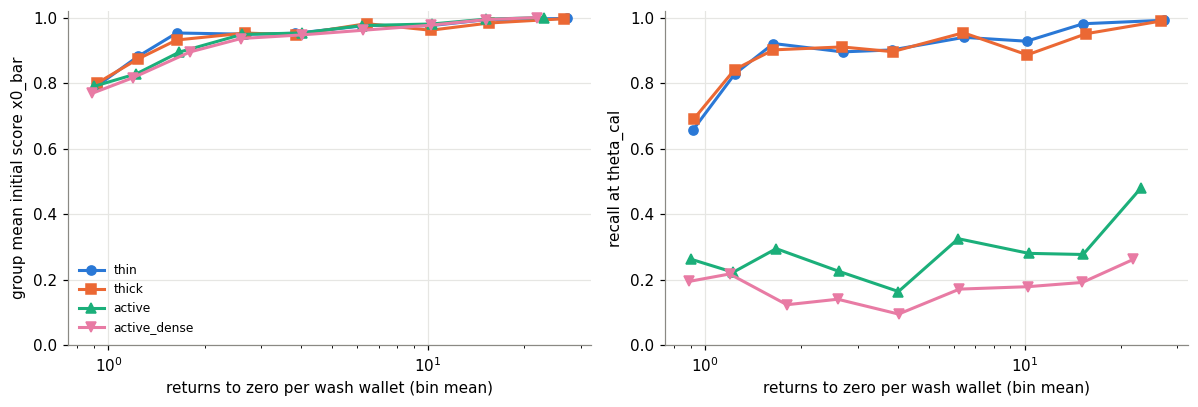

In [8]:
gr = pd.read_csv(det_path("evasive", "groups"),
                 usecols=["config", "run_id", "x0_bar", "x_bar", "leak"])
gr = gr[gr["config"] == "paper"].drop(columns="config")
d = w[w.f_gap == 0].merge(gr, on="run_id")
bins = [0, 0.5, 1, 1.5, 2, 3, 5, 8, 12, 20, 40]
d["bin"] = pd.cut(d["zero_returns_per_used_wallet"], bins, include_lowest=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for ax, (col, ylab) in zip(axes, [("x0_bar", "group mean initial score x0_bar"),
                                  ("trade_recall", "recall at theta_cal")]):
    for b in BG4:
        s = d[d.f_background == b]
        t = s.groupby("bin", observed=True).agg(x=("zero_returns_per_used_wallet", "mean"),
                                                y=(col, "mean"), n=(col, "size")).reset_index()
        t = t[t["n"] >= 30]
        ax.plot(t["x"], t["y"], color=COLOR[b], marker=MARKER[b], label=b)
    ax.set_xscale("log")
    ax.set_xlabel("returns to zero per wash wallet (bin mean)")
    ax.set_ylabel(ylab)
    ax.set_ylim(0, 1.02)
axes[0].legend(fontsize=8)
fig.tight_layout()

## 7. Single-factor sweeps (gap 0, triads)

Left: `rotation`, the pool size P with cycles of 3. Middle: `size`. Solid lines are Q unit
trades; dashed lines are one block of quantity Q, which no ZI ever trades. Right: `residual`,
with p the share of rounds whose closing edge is off by one unit (d = 1). AP, seed means with 95%
intervals. The y axis starts at 0.6.

In thin and thick every single tactic keeps AP at about 1.00, so the thin line lies under the
thick one. Only the active market reacts: AP falls with the pool size and with unit-split size.

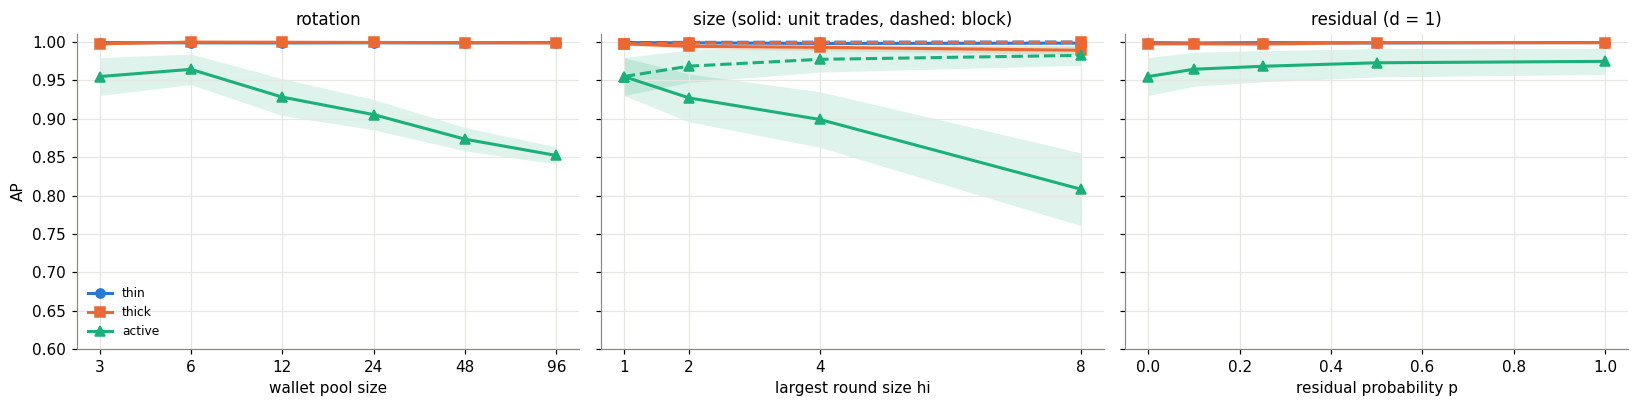

In [9]:
rt, sz, rs = R["rotation"], R["size"], R["residual"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
ax = axes[0]
for b in BG3:
    s = rt[(rt.f_background == b) & (rt.f_cycle_len == 3) & (rt.f_gap == 0)]
    line_ci(ax, mean_ci(s, "f_pool", "trade_avg_precision"), "f_pool", b, b)
ax.set_xscale("log")
ax.minorticks_off()
ax.set_xticks([3, 6, 12, 24, 48, 96], ["3", "6", "12", "24", "48", "96"])
ax.set_xlabel("wallet pool size")
ax.set_ylabel("AP")
ax.set_title("rotation")
ax.legend(fontsize=8, loc="lower left")
ax = axes[1]
for b in BG3:
    for ex, ls in (("units", "-"), ("block", "--")):
        s = sz[(sz.f_background == b) & (sz.f_gap == 0) & ((sz.f_size_exec == ex) | (sz.f_q_hi == 1))]
        line_ci(ax, mean_ci(s, "f_q_hi", "trade_avg_precision"), "f_q_hi", f"{b}, {ex}", b, ls)
ax.set_xticks([1, 2, 4, 8])
ax.set_xlabel("largest round size hi")
ax.set_title("size (solid: unit trades, dashed: block)")
ax = axes[2]
for b in BG3:
    s = rs[(rs.f_background == b) & (rs.f_gap == 0) & ((rs.f_residual_max == 1) | (rs.f_residual_prob == 0))]
    line_ci(ax, mean_ci(s, "f_residual_prob", "trade_avg_precision"), "f_residual_prob", b, b)
ax.set_xlabel("residual probability p")
ax.set_title("residual (d = 1)")
for ax in axes:
    ax.set_ylim(0.6, 1.01)
fig.tight_layout()

## 8. Camouflage and gap in the full factorial

`evasive` wash cells: AP averaged over the other tactics, by gap and camouflage.

In [10]:
display(w.assign(camouflage=np.where(w.f_camouflage_total > 0, "on", "off"))
        .groupby(["f_background", "f_gap", "camouflage"])["trade_avg_precision"].mean()
        .unstack(["camouflage"]).round(2).reindex(BG4, level=0))

camouflage           off    on
f_background f_gap            
thin         0.0    1.00  0.92
             5.0    0.99  0.87
             20.0   0.95  0.71
thick        0.0    0.99  0.93
             5.0    0.96  0.82
             20.0   0.82  0.55
active       0.0    0.85  0.63
             5.0    0.45  0.25
             20.0   0.14  0.07
active_dense 0.0    0.73  0.47
             5.0    0.18  0.10
             20.0   0.09  0.05

## 9. Summary (200 seeds per cell, `paper` config)

1. **Thresholds.** Holding the pooled control FPR at 1% needs $\theta_{cal}$ = 0.84 (thin) and
   0.81 (thick), but 0.97–0.99 in the active backgrounds. At the paper's $\theta = 0.9$ the
   active backgrounds flag 42–44% of honest volume (14% in active_thin). Without propagation, no
   threshold reaches 1%.
2. **Single tactics barely matter in thin and thick.** At gap 0, AP stays at 0.99–1.00 and recall
   at $\theta_{cal}$ stays at 0.91–1.00 for every single tactic. This holds even for pool 96,
   where a wash wallet returns to zero about 1.5 times instead of about 30.
3. **The reason is that the initial score is binary.** One closure is enough for $x^0 = 1$. A
   residual alone does not prevent closures either: wallets cross zero again in their next
   round (about 25 returns per wallet instead of about 30).
4. **Combining tactics is what works.** Pool 96 with Q in 1..4 and residuals leaves about one
   return to zero per wash wallet. Recall at $\theta_{cal}$ then falls to 0.74 (thin) and
   0.76 (thick).
   - Adding camouflage brings it to 0.65 / 0.69.
   - With gap 20 it falls further, to 0.37 / 0.34. AP is then 0.77 / 0.59.
5. **Active markets.** Detection is already weak against the fixed triad: recall at
   $\theta_{cal}$ is 0.45 (active) and 0.30 (active_dense). The honest wallets' own closures,
   not the wash wallets', are the bottleneck. All four tactics reduce AP to 0.53 / 0.38 and
   recall to 0.08 / 0.09.
6. **Camouflage and gap.** Camouflage is the strongest add-on: averaged over the other tactics,
   AP at gap 0 falls from 1.00 to 0.92 (thin) and from 0.85 to 0.63 (active). Its effect grows
   with the gap: at gap 20 thick falls from 0.82 to 0.55.

Implication for the detector: a closure-count or near-zero-position score, rather than the
binary "ever closed", would make the combined adversary's job harder.